<a href="https://colab.research.google.com/github/kr7/dskim1600/blob/main/kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt

from google.colab import widgets
from typing import Tuple

from sklearn.metrics.pairwise import euclidean_distances

In [2]:
!pip install ucimlrepo

In [77]:
# Laden der Kreditkartendaten aus UCI Repository
from ucimlrepo import fetch_ucirepo

def normalize(X):
  return (X-np.mean(X))/np.std(X)

dataset = fetch_ucirepo(id=350)
data = np.zeros( (len(dataset.data.features), 2) )
data[:,0] = normalize(dataset.data.features["X5"]) # Alter
data[:,1] = normalize(dataset.data.features["X1"]) # Kreditbetrag

In [76]:
# "Micky" Daten
# Diese Zelle sollte nur ausgeführt werden, wenn man nicht mit den Kreditkartendaten
# arbeiten möchte, sondern mit diesen generierten Daten

def valid(x):
  return (x[0]**2+x[1]**2<1)

data0 = np.random.rand(10000,2)*2-1
data1 = np.random.rand(2500,2)*2-1
data2 = np.random.rand(2500,2)*2-1
data=[]
for d in data0:
  if valid(d):
    data.append(d)

for d in data1:
  if valid(d):
    data.append(0.6*d+np.array([-0.9,1.75]))

for d in data2:
  if valid(d):
    data.append(0.6*d+np.array([+0.9,1.75]))

data = np.array(data)

In [81]:
# k-means

def initial_centroids(data, num_clusters):
  #return data[(0,18245,2197), :]
  #return data[(0,8000,10000), :] # Zentroide in den drei verschiedenen Kreisen im Falle des "Micky" Datensatzes
  return data[(0,1,2), :]
  #return data[np.random.choice(data.shape[0], num_clusters, replace=False), :] # Zufällige Zentroide

def calculate_clusters_of_instances(data, centroids):
  return np.argmin(euclidean_distances( data, centroids ), axis=1)

def calculate_new_centroids(data, clusters_of_instances, num_clusters):
  new_centroids = np.zeros( (num_clusters, len(data[0])) )
  for c in range(num_clusters):
    new_centroids[c,:] = np.mean(data[clusters_of_instances==c], axis=0)
  return new_centroids

num_iterations = 10
num_clusters = 3
centroids = initial_centroids(data, num_clusters)
clusters_of_instances_per_iteration = []
centroids_per_iteration = []
for i in range(num_iterations):
  centroids_per_iteration.append(centroids)

  clusters_of_instances = calculate_clusters_of_instances(data, centroids)
  centroids = calculate_new_centroids(data, clusters_of_instances, num_clusters)

  clusters_of_instances_per_iteration.append(clusters_of_instances)

In [82]:
# Die Farben der Instanzen wird der jeweiligen Clusterzugehörigkeit entsprechen

def get_color(c):
  if c==0:
    return 'r'
  if c==1:
    return 'b'
  return 'y'

def get_all_colors(clusters_of_instances):
  return [get_color(c) for c in clusters_of_instances]

colors_per_iteration = []
for i in range(num_iterations):
  colors_per_iteration.append(get_all_colors(clusters_of_instances_per_iteration[i]))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

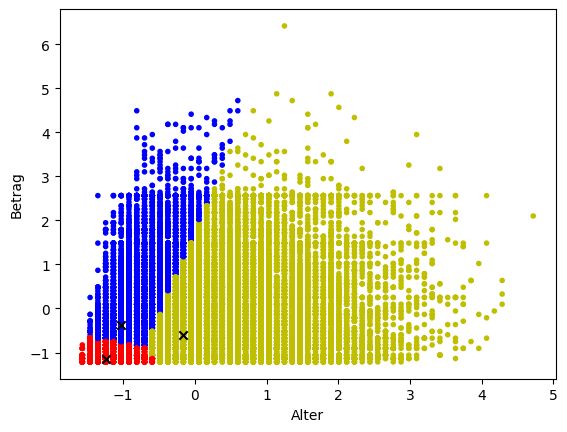

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

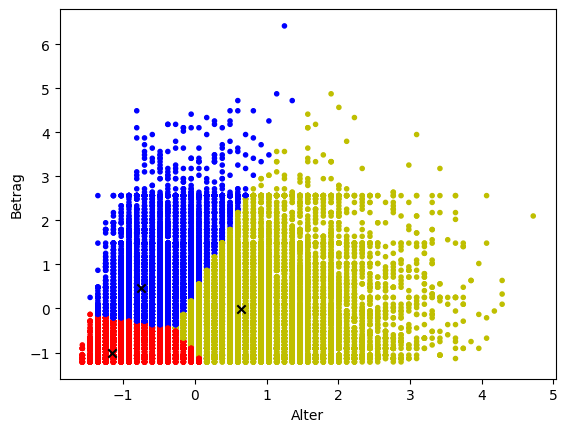

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

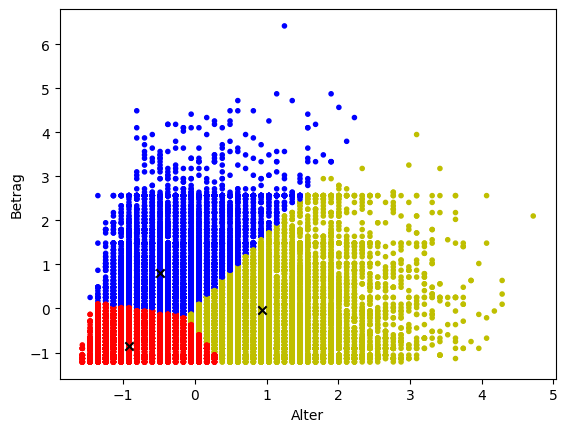

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

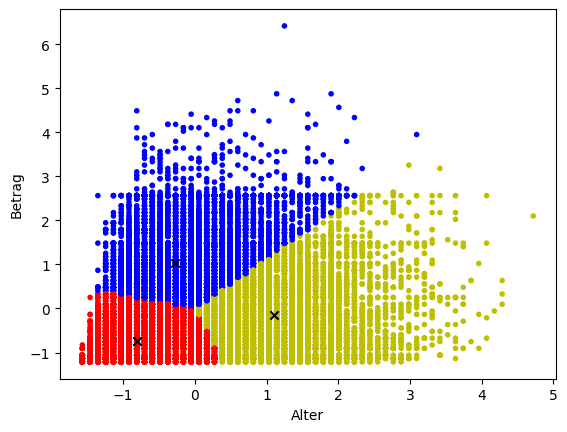

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

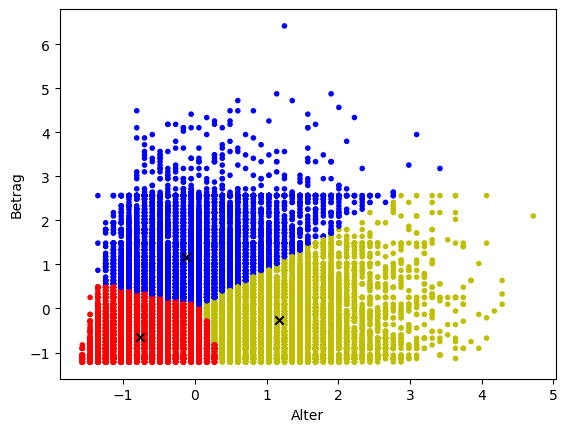

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

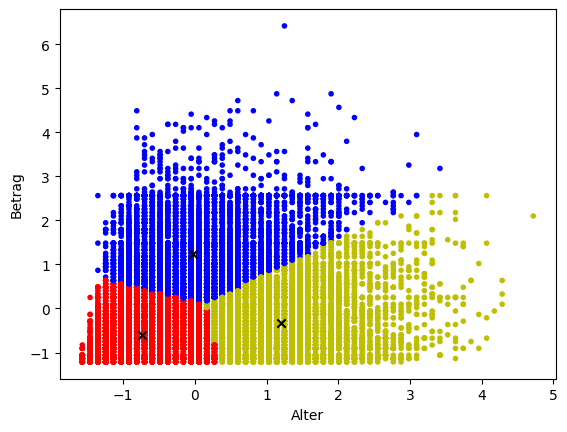

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

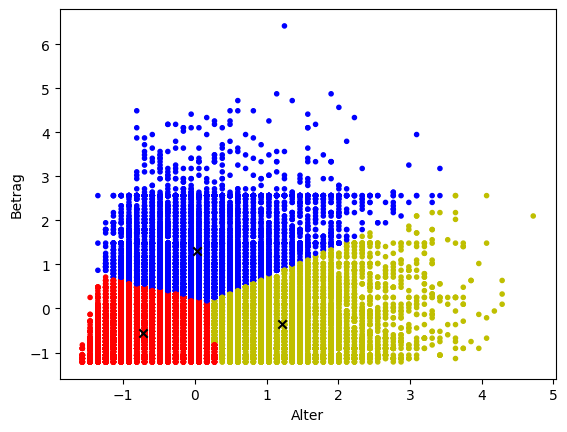

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

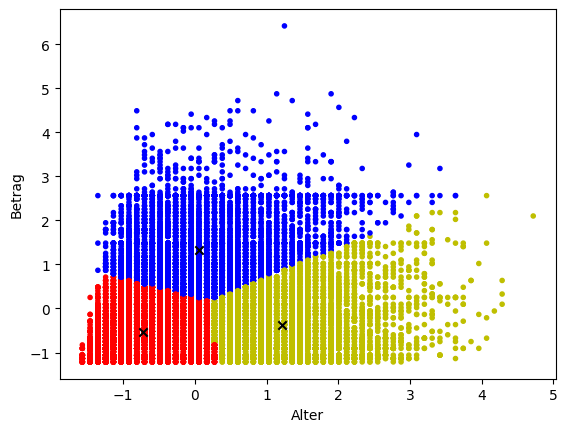

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

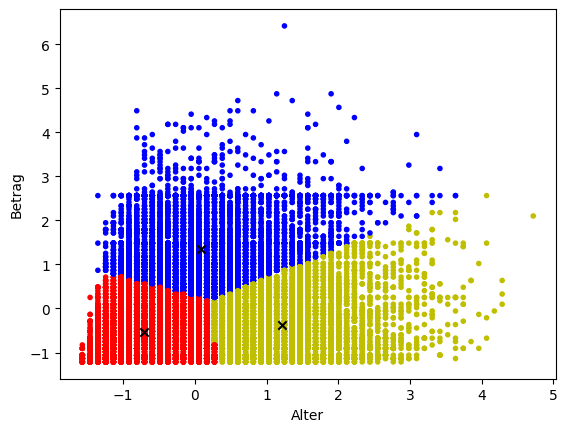

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

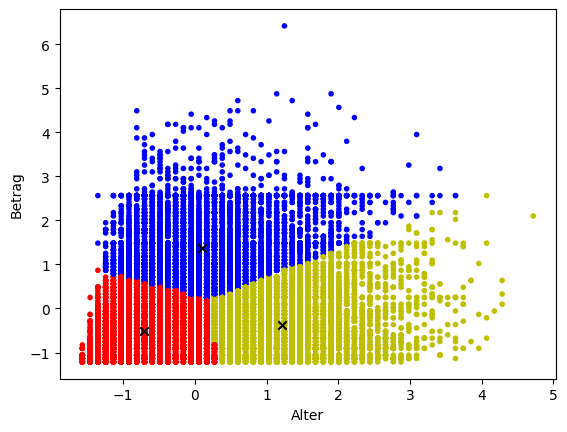

<IPython.core.display.Javascript object>

In [83]:
import matplotlib.pyplot as plt

tb = widgets.TabBar( [int(j) for j in list(np.array(range(10))+1)] , location='top')

for i in range(num_iterations):
  with tb.output_to(i):
    plt.scatter(data[:,0], data[:,1], c=colors_per_iteration[i], marker='.')
    plt.scatter(centroids_per_iteration[i][:,0], centroids_per_iteration[i][:,1], c='k', marker='x')
    plt.xlabel('Alter')
    plt.ylabel('Betrag')
    plt.show()